# EDA - WWI Sales

Sales data for Wide World Importers (2013 - 2016).
I'm using the cleaned file from the Excel step.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_excel("../data/cleaned/Cleaned_Data.xlsx", sheet_name=None, keep_default_na=False, na_values=[""])
sales = data["FactSale"]
customers = data["DimCustomer"]
products = data["DimStockItem"]
employees = data["DimEmployee"]
cities = data["DimCity"]

In [2]:
sales.head()

,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Invoice Date Key,Delivery Date Key,Salesperson Key,WWI Invoice ID,Description,...,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Profit Margin %,Is Loss,Is Outlier
0,49265,41568,0,0,204,2013-10-22,2013-10-23,83,15189,DBA joke mug - mind if I join you? (White),...,15,78.0,11.7,51.0,89.7,6,0,65.38,No,No
1,49372,48937,0,0,173,2013-10-22,2013-10-23,83,15218,Developer joke mug - a foo walks into a bar (B...,...,15,78.0,11.7,51.0,89.7,6,0,65.38,No,No
2,50379,91464,0,0,174,2013-10-28,2013-10-29,70,15525,Developer joke mug - a foo walks into a bar (W...,...,15,78.0,11.7,51.0,89.7,6,0,65.38,No,No
3,51852,48937,0,0,171,2013-11-06,2013-11-07,74,15986,Developer joke mug - this code was generated b...,...,15,78.0,11.7,51.0,89.7,6,0,65.38,No,No
4,52374,89925,0,0,203,2013-11-08,2013-11-09,39,16138,DBA joke mug - mind if I join you? (Black),...,15,78.0,11.7,51.0,89.7,6,0,65.38,No,No


In [3]:
sales.shape

(26397, 23)

## Check the data after cleaning

In [4]:
sales.isnull().sum().sum()

np.int64(0)

In [5]:
sales.duplicated().sum()

np.int64(0)

In [6]:
sales.dtypes

Sale Key                         int64
City Key                         int64
Customer Key                     int64
Bill To Customer Key             int64
Stock Item Key                   int64
Invoice Date Key        datetime64[ns]
Delivery Date Key       datetime64[ns]
Salesperson Key                  int64
WWI Invoice ID                   int64
Description                     object
Package                         object
Quantity                         int64
Unit Price                     float64
Tax Rate                         int64
Total Excluding Tax            float64
Tax Amount                     float64
Profit                         float64
Total Including Tax            float64
Total Dry Items                  int64
Total Chiller Items              int64
Profit Margin %                float64
Is Loss                         object
Is Outlier                      object
dtype: object

## Join the tables

In [7]:
df = sales.merge(customers[["Customer Key", "Customer", "Buying Group"]], on="Customer Key")
df = df.merge(products[["Stock Item Key", "Is Chiller Stock"]], on="Stock Item Key")
df = df.merge(employees[["Employee Key", "Employee"]], left_on="Salesperson Key", right_on="Employee Key")
df = df.merge(cities[["City Key", "State Province"]], on="City Key")

df["Year"] = df["Invoice Date Key"].dt.year
df["Month"] = df["Invoice Date Key"].dt.to_period("M")
df["Day"] = df["Invoice Date Key"].dt.day_name()
df.shape

(26397, 32)

## Main numbers

In [8]:
revenue = df["Total Excluding Tax"].sum()
profit = df["Profit"].sum()
invoices = df["WWI Invoice ID"].nunique()

print("Revenue:", round(revenue))
print("Profit:", round(profit))
print("Margin %:", round(profit / revenue * 100, 1))
print("Invoices:", invoices)
print("Avg invoice:", round(revenue / invoices))

Revenue: 19879593
Profit: 9923892
Margin %: 49.9
Invoices: 8188
Avg invoice: 2428


## Statistics

In [9]:
df[["Quantity", "Unit Price", "Total Excluding Tax", "Profit"]].describe()

,Quantity,Unit Price,Total Excluding Tax,Profit
count,26397.000000,26397.000000,26397.000000,26397.000000
mean,38.969201,44.775579,753.100458,375.947710
std,54.119390,135.170950,1444.947561,762.047362
min,1.000000,0.660000,3.200000,-645.000000
25%,5.000000,13.000000,96.000000,50.400000
50%,10.000000,18.000000,226.800000,120.000000
75%,60.000000,32.000000,864.000000,390.000000
max,360.000000,1899.000000,18990.000000,9200.000000


In [10]:
df[["Quantity", "Unit Price", "Total Excluding Tax", "Profit"]].skew()

Quantity                2.081985
Unit Price             11.283600
Total Excluding Tax     5.279103
Profit                  5.367918
dtype: float64

The data is right skewed, the mean is much bigger than the median.

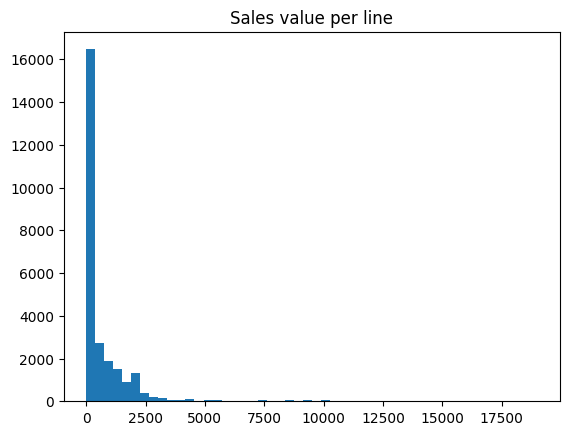

In [11]:
plt.hist(df["Total Excluding Tax"], bins=50)
plt.title("Sales value per line")
plt.show()

## Outliers (IQR)

In [12]:
q1 = df["Total Excluding Tax"].quantile(0.25)
q3 = df["Total Excluding Tax"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = df[df["Total Excluding Tax"] > upper]
print("upper limit:", upper)
print("outliers:", len(outliers))

upper limit: 2016.0
outliers: 2337


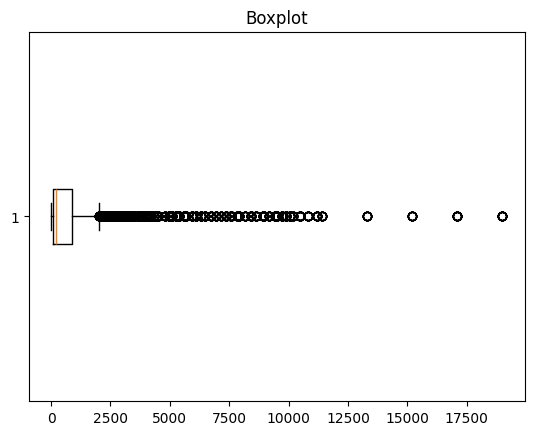

In [13]:
plt.boxplot(df["Total Excluding Tax"], vert=False)
plt.title("Boxplot")
plt.show()

In [14]:
outliers.sort_values("Total Excluding Tax", ascending=False)[["Description", "Quantity", "Total Excluding Tax"]].head(10)

,Description,Quantity,Total Excluding Tax
15944,Air cushion machine (Blue),10,18990.0
11462,Air cushion machine (Blue),10,18990.0
12582,Air cushion machine (Blue),10,18990.0
3886,Air cushion machine (Blue),10,18990.0
10328,Air cushion machine (Blue),10,18990.0
8026,Air cushion machine (Blue),10,18990.0
3623,Air cushion machine (Blue),10,18990.0
11709,Air cushion machine (Blue),10,18990.0
12331,Air cushion machine (Blue),10,18990.0
7512,Air cushion machine (Blue),10,18990.0


These are big real orders so I kept them.

## Lines with loss

In [15]:
loss = df[df["Profit"] < 0]
print(len(loss), "lines with loss")
loss.groupby("Description")["Profit"].sum().sort_values().head(10)

566 lines with loss


Description
Halloween zombie mask (Light Brown) M                  -9024.0
Halloween zombie mask (Light Brown) S                  -8904.0
Halloween zombie mask (Light Brown) XL                 -7884.0
Halloween zombie mask (Light Brown) L                  -7248.0
USB food flash drive - dim sum 10 drive variety pack   -3211.5
USB food flash drive - dessert 10 drive variety pack   -1590.0
USB food flash drive - chocolate bar                    -439.2
USB food flash drive - hot dog                          -380.0
USB missile launcher (Green)                            -273.5
USB food flash drive - sushi roll                       -266.4
Name: Profit, dtype: float64

## Correlation

In [16]:
df[["Quantity", "Unit Price", "Total Excluding Tax", "Profit"]].corr()

,Quantity,Unit Price,Total Excluding Tax,Profit
Quantity,1.000000,-0.135578,0.237709,0.225987
Unit Price,-0.135578,1.000000,0.522938,0.414257
Total Excluding Tax,0.237709,0.522938,1.000000,0.951158
Profit,0.225987,0.414257,0.951158,1.000000


## Sales by year

In [17]:
yearly = df.groupby("Year")[["Total Excluding Tax", "Profit"]].sum()
yearly

,Total Excluding Tax,Profit
Year,,
2013,5257954.55,2637740.90
2014,5843423.25,2908058.35
2015,6347855.45,3162081.75
2016,2430359.55,1216010.70


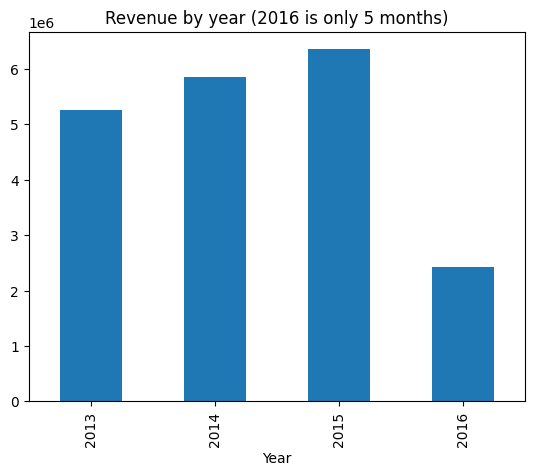

In [18]:
yearly["Total Excluding Tax"].plot(kind="bar")
plt.title("Revenue by year (2016 is only 5 months)")
plt.show()

## Sales by month

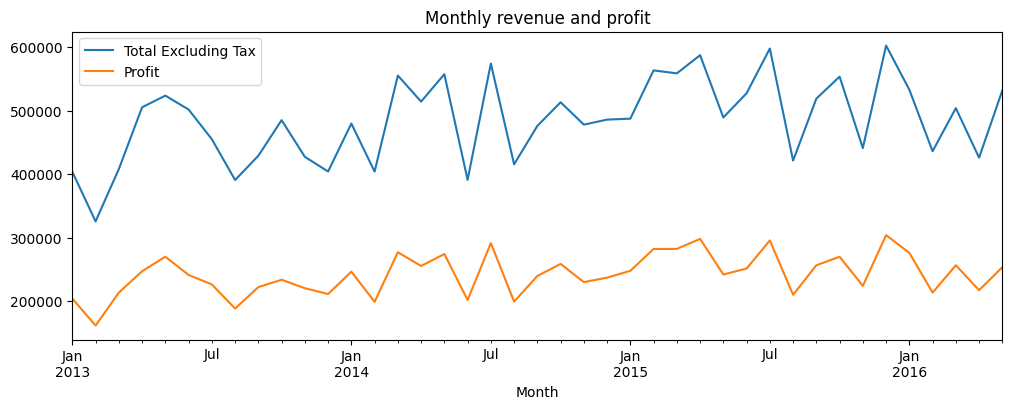

In [19]:
monthly = df.groupby("Month")[["Total Excluding Tax", "Profit"]].sum()
monthly.plot(figsize=(12, 4))
plt.title("Monthly revenue and profit")
plt.show()

## Sales by day

In [20]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("Day")["Total Excluding Tax"].sum().reindex(days)
by_day

Day
Monday       3823629.75
Tuesday      3677955.35
Wednesday    3636756.70
Thursday     3469929.80
Friday       3504287.30
Saturday     1767033.90
Sunday              NaN
Name: Total Excluding Tax, dtype: float64

No sales on Sunday.

## Top products

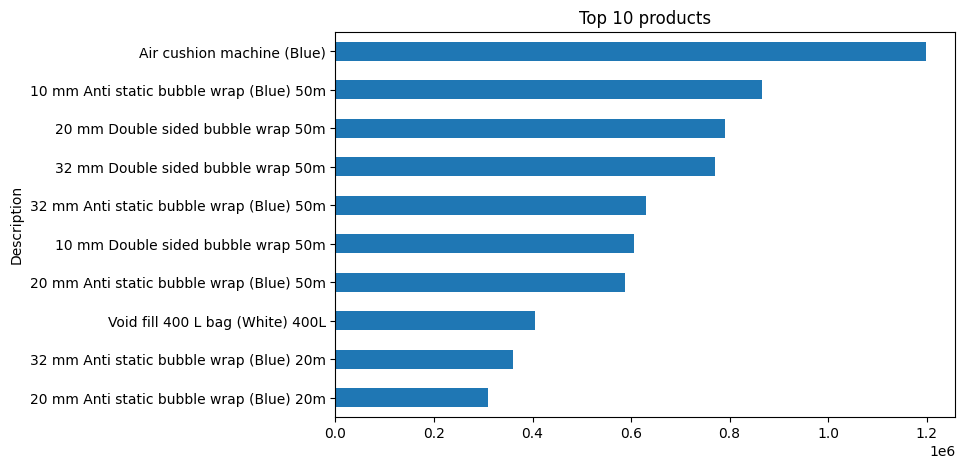

In [21]:
top_products = df.groupby("Description")["Total Excluding Tax"].sum().sort_values(ascending=False).head(10)
top_products.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 products")
plt.show()

## Salespeople

In [22]:
df.groupby("Employee")["Total Excluding Tax"].sum().sort_values(ascending=False)

Employee
Sophia Hinton         2219627.80
Lily Code             2112719.25
Kayla Woodcock        2081322.80
Taj Shand             2008877.10
Archer Lamble         2005033.50
Hudson Hollinworth    1983751.50
Hudson Onslow         1915478.25
Amy Trefl             1890399.35
Anthony Grosse        1873637.70
Jack Potter           1788745.55
Name: Total Excluding Tax, dtype: float64

## Buying group

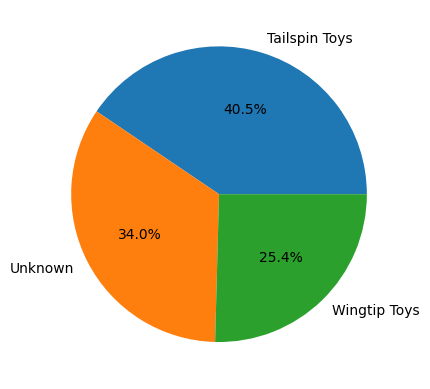

In [23]:
groups = df.groupby("Buying Group")["Total Excluding Tax"].sum()
groups.plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("")
plt.show()

## States

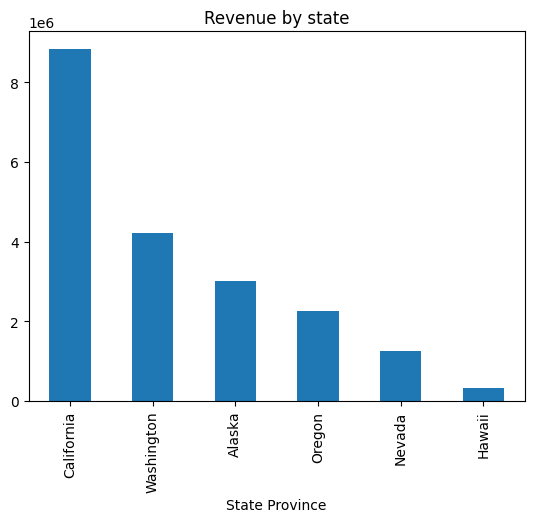

In [24]:
states = df.groupby("State Province")["Total Excluding Tax"].sum().sort_values(ascending=False)
states.plot(kind="bar")
plt.title("Revenue by state")
plt.show()

## Chiller vs dry

In [25]:
df.groupby("Is Chiller Stock")[["Total Excluding Tax", "Profit"]].sum()

,Total Excluding Tax,Profit
Is Chiller Stock,,
No,19750457.2,9867248.1
Yes,129135.6,56643.6


## Insights

- Revenue grows about 10% every year and the margin stays around 50%.
- Packaging products (bubble wrap, air cushion machine) sell the most.
- Halloween masks are always sold at a loss.
- 34% of sales have no customer name (Unknown).
- California is 44% of revenue.
- No sales on Sunday.